# AEGIS: training, evaluation, privacy audit and sampling

In this notebook we train AEGIS, use it to continue a health trajectory, check how well its predicted rates and
waiting times are calibrated, measure its accuracy (age- and sex-stratified AUC), test whether it memorized anyone,
and sample synthetic patients from it. The method itself is in `aegis/`. The two files next to this notebook hold
the rest: `simulation.py` builds the simulated cohort, and `analysis.py` does the evaluation and draws the figures.

The paper used [UK Biobank](https://www.ukbiobank.ac.uk) data, which we cannot share, so here we simulate 500,000
people. Half of them (250,000, close to the paper's 251,204) are training members, so DP-SGD runs with the same
sampling rate and number of steps as in the paper. We built the disease links into the simulation (for example,
tobacco use makes lung cancer 8 times more likely), so we can check whether each model learned them. We train two
models: one without privacy and one with person-level DP-SGD at $\varepsilon$ = 8. Both use the paper's architecture
(12 layers, 12 heads, 120 dimensions, about 2.3 million parameters) and the paper's DP-SGD settings; only the
non-private training settings were chosen for this cohort. A simulation is much simpler than real health records,
so the numbers you will see are not the paper's results and need not match them; those are in its figures and
Supplementary Data 1.

Before the first run, install the requirements as the README explains, and start Jupyter from this folder so that
`aegis/` can be imported. A full run takes about 100 minutes on a GPU. Without a GPU, the notebook switches to 20,000
people and a smaller 2-layer model; this takes about an hour on a CPU, and the models then learn fewer of the links.

## 1. Setup

We import the AEGIS code, the simulation and the analysis functions, and choose the size of the run. On a GPU we
use the paper's architecture on 500,000 people; on a CPU we fall back to a 2-layer model on 20,000 people, since the
12-layer model would take hours there.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import torch

from aegis.data import Cohort, Vocab, Packed, make_splits, planted_pool, make_planted
from aegis.model import PRESETS
from aegis.train import train
from aegis.audit import run_audit, person_groups
from aegis.synthetic import ModelGenerator, dp_real_rate, calibrate, window_rate
from simulation import simulate, caused_codes, first_ages, DISEASES, LINKS
from analysis import *

Opacus warns that its secure random generator is off; we keep it off, as in most research use (see the README), and
hide the warning together with tqdm's note about notebook widgets.

In [2]:
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', message='IProgress not found')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

The two settings of the run. The learning rate of the 12-layer model is lower than that of the 2-layer one, as
deeper transformers are less stable at high rates. DP-SGD uses the paper's settings: an expected batch of 4,096
people, the value that was best in the tuning for the paper, a learning rate of $10^{-2}$, 30 epochs and
$\delta = 10^{-6}$. With about 250,000 training histories this gives the paper's sampling rate, $q$ = 1/62, and its
1,860 steps.

In [3]:
GPU = dict(n_people=500000, arch='delphi2m', max_events=64,
           epochs=40, batch=128, lr=1e-3, warmup=500, weight_decay=0.01, patience=5,
           dp_epochs=30, dp_batch=4096, phys_batch=256, dp_lr=1e-2, delta=1e-6)
SMALL = dict(n_people=20000, arch='tiny', max_events=32,
             epochs=40, batch=64, lr=3e-3, warmup=100, weight_decay=0.01, patience=5,
             dp_epochs=40, dp_batch=256, phys_batch=256, dp_lr=3e-3, delta=1e-6)
RUN = GPU if DEVICE == 'cuda' else SMALL
#RUN = dict(GPU, n_people=200000)  
N_PEOPLE = RUN['n_people']

In [4]:
# train() reseeds for every model; this seed covers anything drawn before it
torch.manual_seed(0)
set_style()
V = Vocab()
T0 = time.time()
DEVICE, N_PEOPLE, RUN['arch'], PRESETS[RUN['arch']]

('cuda', 500000, 'delphi2m', {'n_layer': 12, 'n_head': 12, 'n_embd': 120})

## 2. A simulated cohort with known disease links

We give each simulated person a sex at birth, lifestyle at an assessment visit between 40 and 70 years (smoking, BMI
and alcohol, the lifestyle tokens of Delphi), first occurrences of 29 ICD-10 codes, and death. The three childhood
codes (chickenpox, tonsillitis and asthma) can occur from birth and the others from 18 years, so that no child is
recorded with tobacco use or depression. Every code has a yearly rate that changes with age and sex; the links
multiply the rate of an outcome after its exposure, and some diseases raise the rate of death. We follow people from
birth to death or to 2022 (birth years 1937-1970), as in UK Biobank. The tables of rates and links are at the top of
`simulation.py`; the vocabulary is AEGIS's fixed public one of 1,714 tokens, of which the 29 codes are a small part.

In [5]:
cohort, CODES = simulate(N_PEOPLE, seed=0)
CAUSED = caused_codes()

We name each token by its code and disease, and keep the list of the 29 codes and death that every later analysis
loops over.

In [6]:
NAME = {V.stoi[c]: c + ' ' + DISEASES[c][0] for c in CODES}
NAME[V.death] = 'Death'
TOKS = [V.stoi[c] for c in CODES] + [V.death]

How common is each record? A first look at the cohort tells us how many cases each analysis will have to work with.

In [7]:
counts_all = cohort.token_counts(V.size)
pd.DataFrame({'people with the record': [counts_all[t] for t in TOKS]}, index=[NAME[t] for t in TOKS])

,people with the record
B01 Chickenpox,246558
J03 Tonsillitis,140804
J45 Asthma,106159
F32 Depression,117310
F41 Anxiety,106148
F17 Tobacco use,90552
F10 Alcohol use disorder,36066
E66 Obesity,141085
E78 Hypercholesterolaemia,140876
I10 Hypertension,225313


We split the people once, by person, into training members, a validation set, test participants, audit non-members
and a reference set for the reference-model attack. A person's records are never split across sets.

We build the planted patients as artificial histories of six codes drawn from the rarest codes of the members, so
that they stand out as much as possible, plant 200 of them once in the training data and 50 eight times, and keep 200
aside. Planted and kept-aside patients differ only in whether the model saw them, so an attack that separates them
measures memorization. The paper drew eight codes from the 371 rarest of 1,054 codes, each held by a few dozen
participants. The simulation has only 29 codes, all of them common, so `planted_pool` falls back to the 18 rarest,
and our planted patients stand out far less than the paper's: we expect the attacks on them to be weaker here.

In [8]:
splits = make_splits(len(cohort), seed=0)
members, val, test = (cohort.subset(splits[k]) for k in ('members', 'val', 'test'))
nonmembers, reference = cohort.subset(splits['audit']), cohort.subset(splits['reference'])
counts = members.token_counts(V.size)

In [9]:
pool = planted_pool(counts, 'rare', 6)
planted = {}
planted['in1'] = make_planted(pool, 200, 6, np.random.default_rng(0))
planted['in8'] = make_planted(pool, 50, 6, np.random.default_rng(1))
planted['out'] = make_planted(pool, 200, 6, np.random.default_rng(2))

In [10]:
training_data = Cohort.concat([members, planted['in1'], planted['in8'].repeat(8)])
pd.Series({k: len(v) for k, v in splits.items()} | {'training histories': len(training_data)})

members               250000
val                    25000
test                   75000
audit                  50000
reference             100000
training histories    250600
dtype: int64

One simulated test participant, age in years and record:

In [11]:
history_table(test, 3, NAME, V)

,age,record
0,0.0,<male>
1,15.5,J45 Asthma
2,39.6,E11 Type 2 diabetes
3,40.0,F17 Tobacco use
4,43.0,K57 Diverticular disease
5,67.2,BMI_low
6,67.2,Smoking_high
7,67.2,Alcohol_mid
8,73.9,C34 Lung cancer
9,76.4,I48 Atrial fibrillation


## 3. Training without privacy and with DP-SGD

We train both models with the AEGIS architecture: the per-person loss, the ICD-10 hierarchy embeddings and the public
starting rate. We train the non-private model with AdamW, batches of 128 people, up to 40 epochs and early stopping on
the validation loss, and the private one with person-level DP-SGD in [Opacus](https://opacus.ai): every history
enters a step with probability $q$ (Poisson sampling), each person's gradient is clipped to norm $C = 1$, Gaussian
noise $\mathcal{N}(0, \sigma^2 C^2)$ is added to the sum, and the RDP accountant sets $\sigma$ before training so that
the privacy loss after the last step is $\varepsilon$ = 8 at $\delta = 10^{-6}$. We use 30 epochs, expected batches
of 4,096 people and a learning rate of $10^{-2}$, as in the paper; there is no early stopping and no dropout, so the
released model is the one after the last accounted step.

In [12]:
# the run's settings, plus the AEGIS choices that are the same in both settings
cfg = dict(RUN)
del cfg['n_people']
cfg.update(dropout=0.0, tie=True, hier=True, loss_unit='person', init_rate='public', clip=1.0)

In [13]:
models, extras = {}, {}
models['non-private'], extras['non-private'] = train(training_data, val, V, cfg, DEVICE, seed=0, label='non-private')

[12:36:43]   non-private: non-private, 2.33M parameters, 250600 training histories
[12:37:50]   non-private epoch 1: train 9.345, validation 9.398
[12:38:56]   non-private epoch 2: train 9.227, validation 9.390
[12:40:03]   non-private epoch 3: train 9.348, validation 9.382
[12:41:09]   non-private epoch 4: train 9.326, validation 9.377
[12:42:12]   non-private epoch 5: train 9.348, validation 9.376
[12:43:19]   non-private epoch 6: train 9.374, validation 9.372
[12:44:23]   non-private epoch 7: train 9.232, validation 9.372
[12:45:28]   non-private epoch 8: train 9.347, validation 9.371
[12:46:31]   non-private epoch 9: train 9.353, validation 9.369
[12:47:34]   non-private epoch 10: train 9.381, validation 9.370
[12:48:37]   non-private epoch 11: train 9.323, validation 9.369
[12:49:40]   non-private epoch 12: train 9.313, validation 9.368
[12:50:44]   non-private epoch 13: train 9.252, validation 9.367
[12:51:50]   non-private epoch 14: train 9.355, validation 9.366
[12:52:57]   non

In [14]:
models[PRIVATE], extras[PRIVATE] = train(training_data, val, V, cfg, DEVICE, epsilon=8, seed=0, label=PRIVATE)
models['non-private'].n_params()

[13:08:54]   DP-SGD, eps = 8: DP-SGD, 2.33M parameters, 250600 training histories
[13:08:55]   DP-SGD, eps = 8: epsilon 8.00, delta 1e-06, noise multiplier 0.826, sampling rate 0.01613 (expected batch 4042), 30 epochs, clip 1.00
[13:09:46]   DP-SGD, eps = 8 epoch 1: train 9.587, validation 9.643, epsilon spent 2.93
[13:10:36]   DP-SGD, eps = 8 epoch 2: train 9.416, validation 9.501, epsilon spent 3.28
[13:11:26]   DP-SGD, eps = 8 epoch 3: train 9.422, validation 9.447, epsilon spent 3.57
[13:12:16]   DP-SGD, eps = 8 epoch 4: train 9.349, validation 9.442, epsilon spent 3.83
[13:13:06]   DP-SGD, eps = 8 epoch 5: train 9.433, validation 9.442, epsilon spent 4.06
[13:13:56]   DP-SGD, eps = 8 epoch 6: train 9.428, validation 9.462, epsilon spent 4.28
[13:14:46]   DP-SGD, eps = 8 epoch 7: train 9.393, validation 9.440, epsilon spent 4.49
[13:15:36]   DP-SGD, eps = 8 epoch 8: train 9.383, validation 9.441, epsilon spent 4.69
[13:16:27]   DP-SGD, eps = 8 epoch 9: train 9.444, validation 9.440

2327314

The loss curves show how far each model got. We expect the privacy loss of DP-SGD to rise with every epoch and to
reach 8 exactly at the last one, since the accountant chose the noise for that.

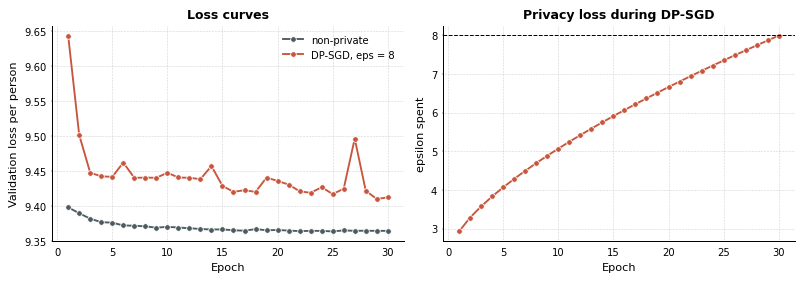

In [15]:
plot_training(extras)

In [16]:
privacy_record(extras)

,epsilon,delta,noise_multiplier,sample_rate,expected_batch,steps,clip
"DP-SGD, eps = 8",7.993158,0.000001,0.825806,0.016129,4041.935484,1860,1.0


## 4. Inference: extrapolating a health trajectory

As in Delphi, we continue a partial trajectory with the model. Every token $k$ gets a waiting time drawn from an
exponential distribution with rate $\lambda_k = e^{l_k}$, the first one happens, and the clock moves on. We take the
records of a test participant before age 60 and let each model continue them to age 80, one draw each, next to what
the participant actually went on to have.

In [17]:
i = pick_participant(test, V)
history_table(test, i, NAME, V, before=60)

,age,record
0,0.0,<male>
1,15.5,J45 Asthma
2,39.6,E11 Type 2 diabetes
3,40.0,F17 Tobacco use
4,43.0,K57 Diverticular disease


In [18]:
history_table(test, i, NAME, V, after=60)

,age,record
0,67.2,BMI_low
1,67.2,Smoking_high
2,67.2,Alcohol_mid
3,73.9,C34 Lung cancer
4,76.4,I48 Atrial fibrillation
5,76.4,Death


In [19]:
continue_from_60(models, test, i, NAME, V, DEVICE)

age                      record
continued by                                       
non-private     0  70.0          K21 Reflux disease
                1  72.3                       Death
DP-SGD, eps = 8 0  68.8  N18 Chronic kidney disease
                1  70.7     M17 Knee osteoarthritis
                2  70.7          K21 Reflux disease
                3  72.2                       Death

At every record the model gives a rate for each disease, and the 1-year risk is $1 - e^{-365.25\,\lambda_k}$. We
follow the predicted risk of four diseases for the same participant; the grey lines mark the participant's
diagnoses, where the predicted risks should move.

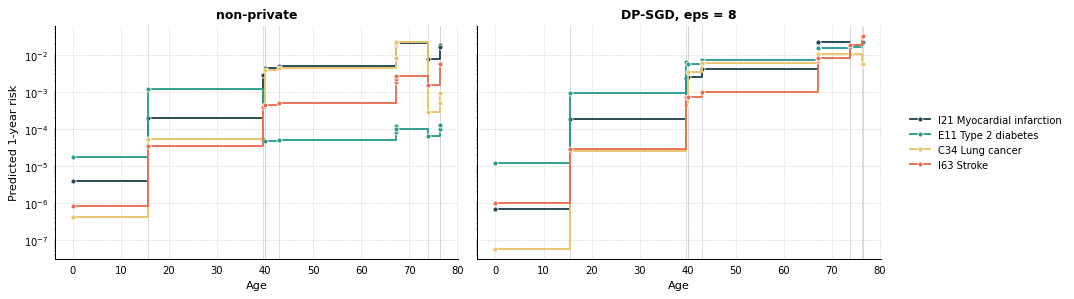

In [20]:
plot_risk_trajectory(models, test, i, ('I21', 'E11', 'C34', 'I63'), NAME, V, DEVICE)

## 5. Calibration of the predicted waiting times

Under competing exponentials the expected time to the next record is $1 / \sum_k \lambda_k$. As in Delphi, we compare
the expected and observed times to the next record over test participants: the grey points are single records and
the line is the mean observed time in bins of the expected time. A calibrated model puts the line on the diagonal.

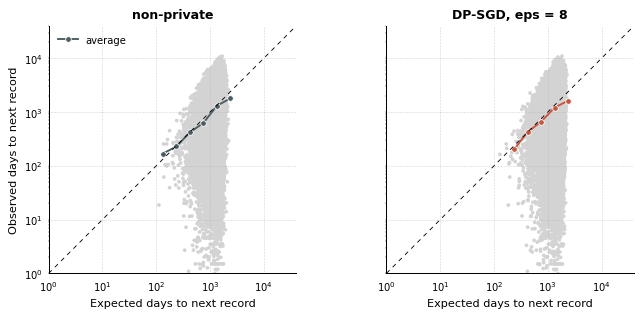

In [21]:
pk_test = Packed(test, cfg['max_events'], DEVICE)
plot_waiting_times(models, pk_test)

## 6. Predicted and observed incidence by age

This is Delphi's age-incidence figure. For five diseases each point is a model's 1-year risk at one record of a test
participant who never has the disease (light colours, a random 5,000 per panel) or at the record just before the
diagnosis (dark colours), coloured by sex. The black line follows one case up to the diagnosis, and the steps give
the observed incidence in the training members by sex, first occurrences per person-year at risk. There is one row
per model.

The clouds can sit above the observed incidence. Records are not a random sample of person-time, as people with
more diagnoses have more records and a higher risk, so we read this figure as a picture of the predictions; the
calibration below compares like with like.

In [22]:
sel = [V.stoi[c] for c in ('I10', 'E11', 'I21', 'C34', 'G30')]
bins = np.arange(0, 86, 5.0)

In [23]:
rec, risk = record_risks(models, pk_test, test, sel)
by_sex = members_by_sex(members)

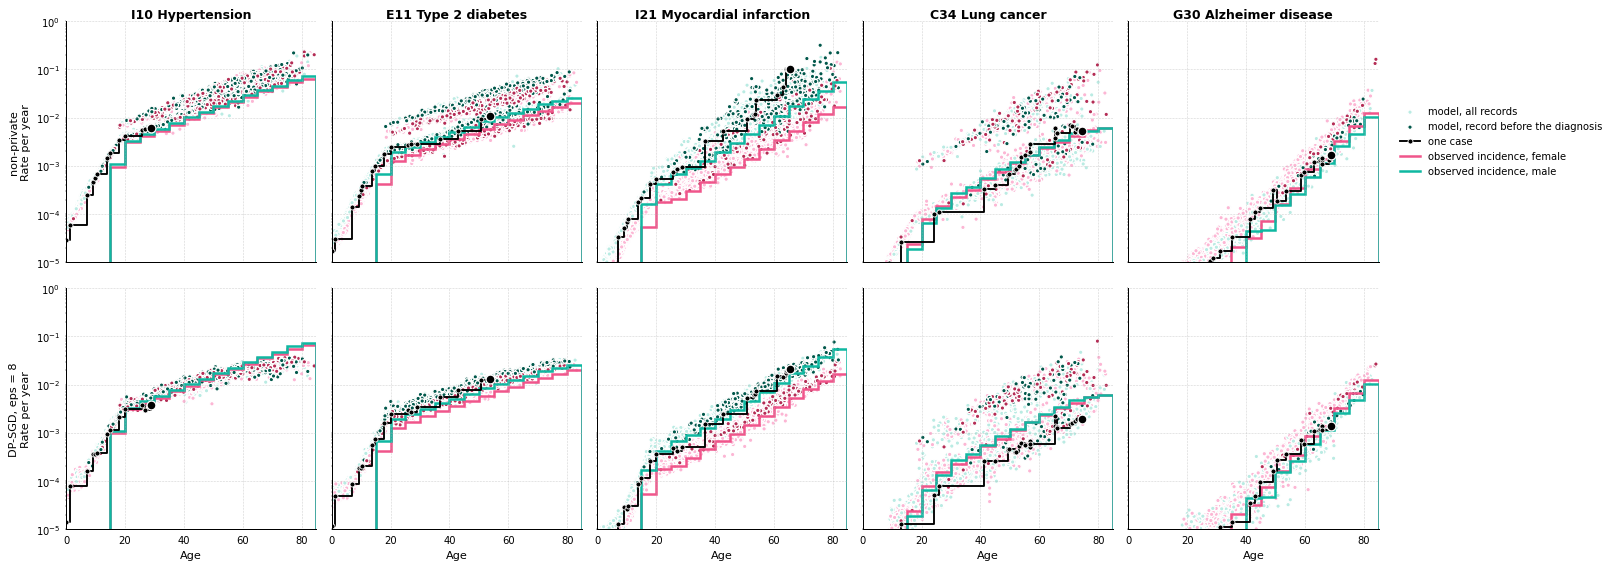

In [24]:
plot_age_incidence(models, rec, risk, test, by_sex, sel, bins, NAME)

For the calibration of the predicted rates we follow Delphi. Test participants who do not have the disease at the
start of a 5-year age bracket (40-80 years) are scored at their last record before it and split into five equal
groups by predicted rate; we compare each group's mean predicted yearly rate with its observed rate in the bracket,
first diagnoses per person-year at risk. Points on the diagonal are calibrated. There is one line per age bracket,
darker for older ages, with women in the top row and men in the bottom row, and one figure per model.

In [25]:
CAL = [V.stoi[c] for c in ('I10', 'E11', 'I21', 'J44', 'C34')]
brackets = np.arange(40, 80, 5)
cal = calibration_data(models, pk_test, test, CAL, brackets)

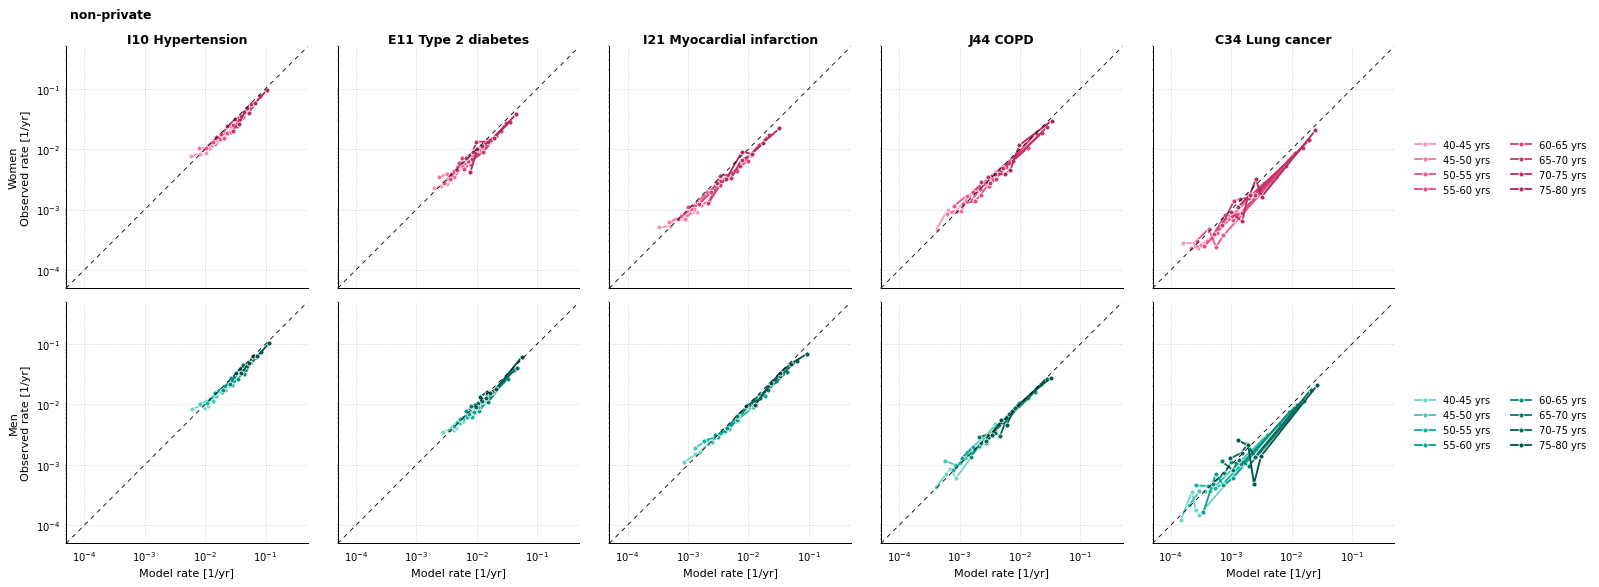

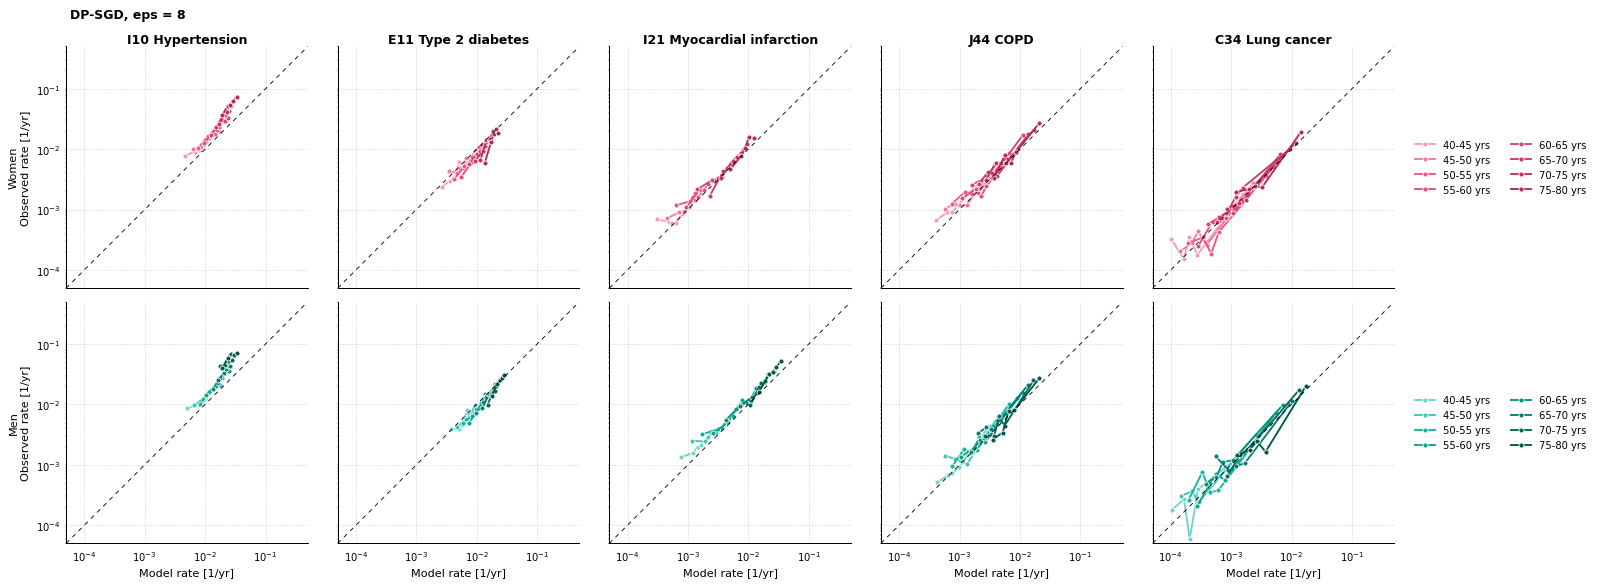

In [26]:
plot_calibration(cal, CAL, brackets, NAME)

## 7. AUC of disease prediction

We score each disease as Delphi and the paper do. A case is scored by the model's rate at the last record more than
0.1 days before the diagnosis, a control (a person who never has the disease) at one random record in each 5-year age
bracket; cases and controls are compared within the brackets (40-80 years) and sex, the AUCs are averaged, and
DeLong's method gives the variance. An AUC of 0.5 means no prediction beyond age and sex.

In the simulation only the codes with an exposure (a link or a lifestyle effect) can be predicted beyond age and
sex; for the others (grey labels below) an AUC close to 0.5 is the right answer. As we know the simulation, we also
score the same cases and controls with the **true rate**, from what each history shows at the time of prediction.
Its AUC is the reference for each disease and checks our evaluation. It is not a strict ceiling, because lifestyle
acts from birth in the simulation but enters the history only at the visit, so a model that infers it from earlier
diagnoses can do slightly better. For the codes with a cause, the gap between a model and the black marker is what
the model has not learned. For the codes without one we expect about 0.5, a little more for the true rate because
of the age trend within a bracket; when a model moves away from it, section 8 ends with checks of three possible
reasons.

We expect alcohol use disorder to be hard, as it would be in UK Biobank. Its only cause is heavy drinking, recorded
at the assessment visit (40-70 years), but most of its diagnoses come earlier in life: only about one in five of them
comes after the drinking record, which leaves the model little to learn the effect from.

In [27]:
auc, scores, truth = auc_table(models, test, TOKS, NAME, counts, CAUSED, V, DEVICE, cfg['max_events'])

In [28]:
columns = ['disease', 'cause', 'training_cases', 'test cases', 'true rate', 'non-private', PRIVATE]
auc[columns].round(3)

,disease,cause,training_cases,test cases,true rate,non-private,"DP-SGD, eps = 8"
0,C34 Lung cancer,True,11610,2944,0.806,0.795,0.792
1,K70 Alcoholic liver disease,True,6330,1250,0.756,0.721,0.567
2,J44 COPD,True,25605,6417,0.751,0.751,0.719
3,Death,True,80643,21862,0.712,0.669,0.717
4,I21 Myocardial infarction,True,31251,8090,0.673,0.670,0.591
5,I50 Heart failure,True,23212,6274,0.669,0.665,0.596
6,E11 Type 2 diabetes,True,55798,12081,0.664,0.646,0.574
7,N18 Chronic kidney disease,True,23866,6447,0.664,0.659,0.576
8,I63 Stroke,True,18923,5145,0.658,0.653,0.587
9,F32 Depression,True,58611,7180,0.625,0.600,0.501


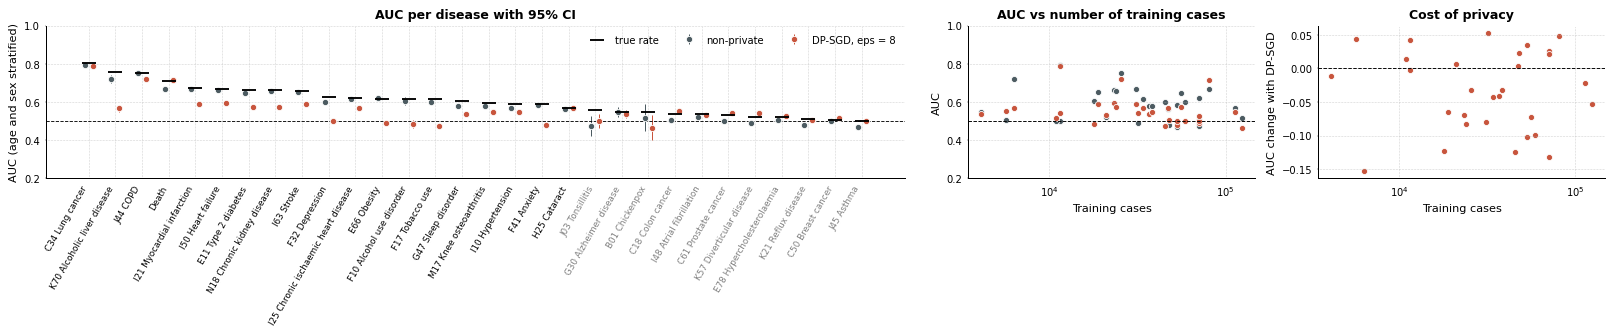

In [29]:
plot_auc(auc, models)

The non-private model comes within 0.04 of the true rate for every code with a cause except death (0.67 against
0.71), and it learns most of the effect of heavy drinking on alcohol use disorder (AUC 0.61 against 0.62 for the
true rate). DP-SGD keeps the accuracy for lung cancer (0.79), COPD (0.72) and death (0.72), as it learned the effect
of tobacco use (section 8). It keeps part of the accuracy for the circulatory codes (0.57 to 0.60 against 0.61 to
0.67 without privacy) and loses most of it for alcoholic liver disease (0.57 against 0.72). For obesity, depression,
anxiety, tobacco use and alcohol use disorder, the AUCs of DP-SGD are 0.48 to 0.50, i.e., no better than age and
sex; the end of section 8 looks at where cases are scored, which moves AUCs around 0.5.

Averaged over the codes, the mean AUC of the codes with a cause is the number to compare with the true rate.

In [30]:
mean_aucs(auc).round(3)

,all codes,codes with a cause
non-private,0.589,0.639
"DP-SGD, eps = 8",0.555,0.575
true rate,NaN,0.652


The ROC curves of six diseases are adjusted for age and sex: each score is replaced by its percentile among the
controls of the same sex and 5-year age bracket, so the curve compares people of the same age and sex, as the AUC
does. The black line is the true rate.

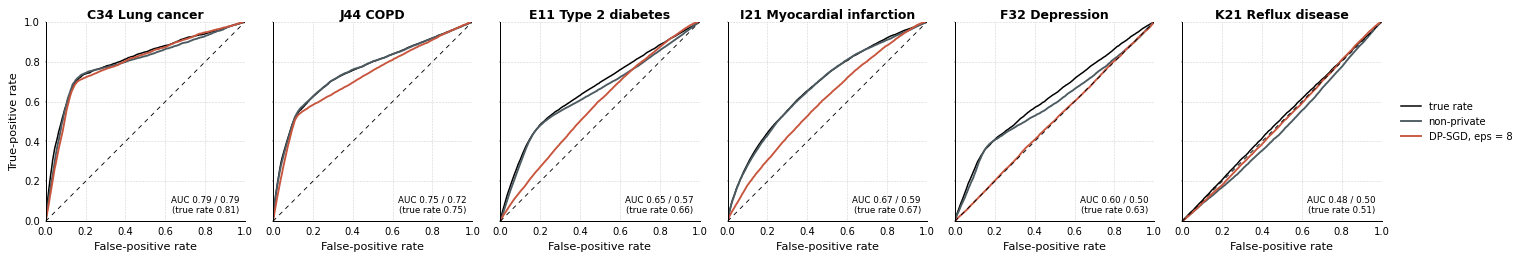

In [31]:
plot_roc(['C34', 'J44', 'E11', 'I21', 'F32', 'K21'], truth, scores, auc, NAME, V)

## 8. Learned disease links

Does the model know that an exposure raises the rate of its outcome? For test participants without the exposure or
the outcome before age 60, we compute the model's rate of the outcome at 60 twice, with their history and with the
exposure added at 59.5 years. The ratio of the two rates, a geometric mean over people, is the effect the model
learned, and we set it against the simulation's true rate ratio.

DP-SGD clips each person's gradient and adds noise, so it learns a link only when enough people carry it, and the
cost of privacy falls with the number of people with a disease, as in the paper. The GPU setting has as many
training members as the paper, but the simulation is much simpler than UK Biobank: apart from age and sex, its only
structure is the 25 links and three lifestyle factors, so a model's accuracy beyond age and sex rests on these links
alone, and the share of it that DP-SGD keeps here need not match the paper's. With the 10,000 training members of the
CPU setting we see DP-SGD learn mainly age and sex.

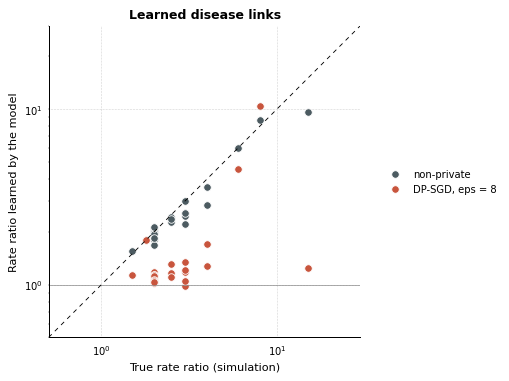

In [32]:
links = link_table(models, test, LINKS, DISEASES, V, DEVICE)
plot_links(links)

The share of the effect (log rate ratio) of the links the non-private model learned, at a rate ratio of 1.5 or more,
that DP-SGD keeps, and the number of those links:

In [33]:
kept_link_effect(links)

(0.32639655174704135, 25)

In [34]:
# with the median age at the first record of each link's exposure in the training members
first = first_ages(members)
exposure_age = [np.median(first[V.stoi[e]][np.isfinite(first[V.stoi[e]])]) / 365.25 for e, o in LINKS]
links.assign(**{'exposure age': exposure_age}).round(2)

,link,true,non-private,"DP-SGD, eps = 8",exposure age
0,Obesity -> Type 2 diabetes,3.0,2.99,1.18,40.48
1,Obesity -> Hypertension,2.0,1.99,1.18,40.48
2,Obesity -> Knee osteoarthritis,2.0,2.03,1.11,40.48
3,Obesity -> Sleep disorder,2.5,2.42,1.16,40.48
4,Hypertension -> Myocardial infarction,2.0,1.99,1.10,52.42
5,Hypertension -> Stroke,2.5,2.28,1.11,52.42
6,Hypertension -> Chronic kidney disease,2.0,2.04,1.14,52.42
7,Hypertension -> Heart failure,2.0,1.95,1.14,52.42
8,Type 2 diabetes -> Myocardial infarction,2.0,1.80,1.13,53.33
9,Type 2 diabetes -> Chronic kidney disease,3.0,2.56,1.21,53.33


The non-private model recovers almost every link, the strong ones included: tobacco use multiplies the rate of lung
cancer by 8.6, as simulated (8). It underestimates the links of myocardial infarction (2.8 and 2.2 against 4 and 3)
and the link of alcohol use disorder with alcoholic liver disease (9.7 against 15). DP-SGD learns the three links of
tobacco use (10.5, 4.6 and 1.8 against 8, 6 and 1.8) and part of the links of myocardial infarction and atrial
fibrillation (1.3 to 1.7), whereas the other links stay at 0.98 to 1.24; altogether it keeps 33% of the learned link
effect. Which links DP-SGD learns does not follow the number of people with the exposure: hypertension is the most
common exposure, with about 113,000 training members, but its links stay at about 1.1. The age at which an exposure
is first recorded (last column) does not explain the pattern either. As the notebook trains one seed, we cannot tell
how much of this pattern is chance.

We check three possible reasons why a model's AUC moves away from 0.5 in the codes without a cause. First, where
cases are scored:
the paper, as Delphi, scores a case at the last record before the diagnosis, and a diagnosis is more likely to fall
into a long gap between records, so that record might not be a typical one; we repeat the AUC with each case scored at
a random record at least one year before the diagnosis. Second, controls scored shortly before they die or leave
follow-up can never become cases, so we repeat the AUC with only the controls followed for at least five more years.
Third, a model could lower every rate after any diagnosis; the last column gives the rate ratio the non-private
model predicts after an unrelated diagnosis is added at 59.5 years (a geometric mean over four other codes without a
cause; the truth is 1). Does any of them bring the AUCs back to 0.5?

In [35]:
no_cause_checks(models, scores, test, TOKS, CAUSED, NAME, V, DEVICE, cfg['max_events']).round(3)

,disease,test cases,non-private,"non-private, cases scored 1+ year before","non-private, controls followed 5+ years","DP-SGD, eps = 8","DP-SGD, eps = 8, cases scored 1+ year before","DP-SGD, eps = 8, controls followed 5+ years",rate ratio after an unrelated diagnosis
0,B01 Chickenpox,131,0.518,0.402,0.516,0.465,0.479,0.464,0.856
1,J03 Tonsillitis,1000,0.472,0.495,0.464,0.499,0.539,0.464,0.926
2,J45 Asthma,3978,0.468,0.515,0.458,0.503,0.541,0.472,0.985
3,E78 Hypercholesterolaemia,13956,0.504,0.513,0.489,0.526,0.518,0.500,1.128
4,K21 Reflux disease,8113,0.481,0.518,0.466,0.504,0.486,0.482,1.076
5,I48 Atrial fibrillation,5585,0.523,0.508,0.514,0.530,0.505,0.537,1.147
6,K57 Diverticular disease,7498,0.488,0.519,0.471,0.541,0.510,0.524,1.123
7,C50 Breast cancer,2111,0.503,0.531,0.493,0.517,0.505,0.505,1.044
8,C61 Prostate cancer,2958,0.502,0.514,0.490,0.544,0.497,0.540,1.016
9,C18 Colon cancer,1418,0.508,0.485,0.496,0.553,0.507,0.537,1.085


Where the cases are scored explains part of the departures from 0.5. Averaged over these codes (leaving out
chickenpox, which has few cases after 40), the non-private model scores 0.50 when a case is scored at the last
record before the diagnosis and 0.51 when it is scored at a random record a year or more before, closer to the AUC
of the true rate (0.53); DP-SGD moves from 0.53 to 0.51. Keeping only the controls followed for five more years
changes little (0.49 and 0.51), and an unrelated diagnosis changes the predicted rates of the non-private model by
15% at most (rate ratios of 0.93 to 1.15). So the record just before a diagnosis is not a typical record, and the
two models respond to it in opposite directions; the same probably explains why the non-private model falls below
the true rate for death. The paper keeps Delphi's scoring so that its AUCs can be compared with Delphi's.

## 9. Privacy audit

We run the five attacks of the paper. Patients planted once and eight times are set against kept-aside patients; the
loss attack sets training members against non-members; the reference-model attack compares a person's loss with
their loss under reference models trained without them, in the manner of [LiRA](https://arxiv.org/abs/2112.03570)
(here two reference models per target, on halves of the reference set, trained with the target's recipe; as in the
paper, the reference models of the private target are private too, at its $\varepsilon$ and sampling rate); and the
psychiatric attack uses the mean
log-probability of the F codes. From the patients planted once, the [one-run audit](https://arxiv.org/abs/2305.08846)
and the threshold method give empirical lower bounds on $\varepsilon$, which must stay below the $\varepsilon$ the
model claims.

In [36]:
refs = {'non-private': reference_models(reference, val, V, cfg, DEVICE),
        PRIVATE: reference_models(reference, val, V, cfg, DEVICE, epsilon=8, n_target=len(training_data))}

[13:34:56]   reference 0: non-private, 2.33M parameters, 50000 training histories
[13:35:09]   reference 0 epoch 1: train 9.363, validation 9.437
[13:35:23]   reference 0 epoch 2: train 9.429, validation 9.425
[13:35:36]   reference 0 epoch 3: train 9.433, validation 9.410
[13:35:49]   reference 0 epoch 4: train 9.299, validation 9.401
[13:36:03]   reference 0 epoch 5: train 9.235, validation 9.398
[13:36:16]   reference 0 epoch 6: train 9.343, validation 9.399
[13:36:29]   reference 0 epoch 7: train 9.389, validation 9.394
[13:36:43]   reference 0 epoch 8: train 9.166, validation 9.390
[13:36:57]   reference 0 epoch 9: train 9.343, validation 9.390
[13:37:11]   reference 0 epoch 10: train 9.240, validation 9.386
[13:37:24]   reference 0 epoch 11: train 9.346, validation 9.385
[13:37:38]   reference 0 epoch 12: train 9.342, validation 9.387
[13:37:51]   reference 0 epoch 13: train 9.300, validation 9.384
[13:38:04]   reference 0 epoch 14: train 9.159, validation 9.384
[13:38:18]   refe

In [37]:
packs, msub = audit_packs(members, nonmembers, planted, cfg['max_events'], DEVICE)
groups = {'members': person_groups(msub, V, counts), 'nonmembers': person_groups(nonmembers, V, counts)}

In [38]:
# the same patients for both models, and for each model reference models trained like it
audits = {}
for name, m in models.items():
    audits[name] = run_audit(m, refs[name], packs, V, cfg['delta'], groups=groups)

[14:05:22]   audit: planted x1 0.74, x8 0.98; loss attack AUC 0.508; reference attack AUC 0.539; psychiatric AUC 0.503; one-run eps >= 0.87
[14:05:42]   audit: planted x1 0.53, x8 0.55; loss attack AUC 0.501; reference attack AUC 0.502; psychiatric AUC 0.498; one-run eps >= 0.00


In [39]:
audit_summary(audits, extras).round(3)

,non-private,"DP-SGD, eps = 8"
planted once: AUC,0.739,0.535
planted 8x: AUC,0.985,0.545
loss attack: AUC,0.508,0.501
reference attack: AUC,0.539,0.502
psychiatric attack: AUC,0.503,0.498
one-run lower bound on eps,0.869,0.000
threshold lower bound on eps,0.999,0.000
claimed eps,NaN,7.993


The non-private model recognises the patients planted eight times almost perfectly (AUC 0.98) and those planted once
in part (0.74), and the one-run audit certifies $\varepsilon \geq 0.9$ for it. Every attack on the DP-SGD model
stays close to chance (AUCs of 0.50 to 0.55), and its empirical bounds on $\varepsilon$ are 0, below the 8 it
claims. The planted patients of the simulation are made of common codes, so even against the non-private model they
stand out less than the paper's patients planted once did (AUC 0.74 here against 0.997 in UK Biobank).

The ROC curves are on log axes, because what matters for privacy is the true-positive rate at a very low
false-positive rate. The planted patients are artificial, so their scores can be shown person by person on the
right.

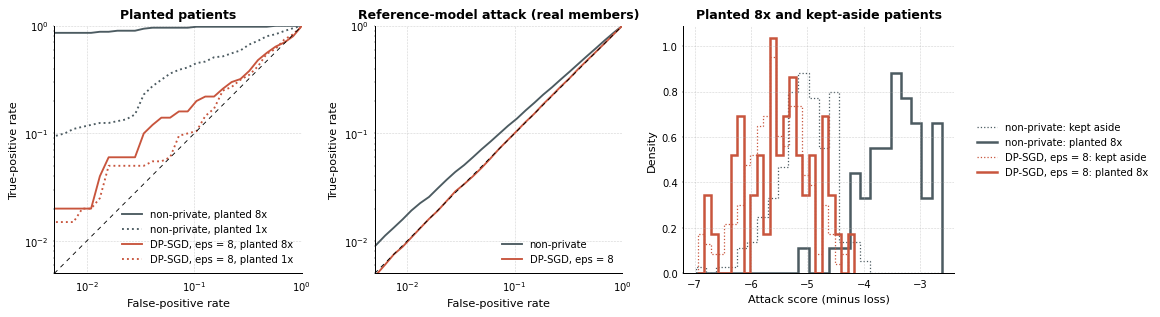

In [40]:
plot_audit(audits, models, packs)

## 10. Sampling into the future

As in Delphi's sampling notebook, we cut the histories of test participants at age 60 and let each model continue
them to 75. We use the people whose outcome by 75 is known, followed to 75 or dead before it, because the sampled
histories also stop at death; with survivors only, the observed shares would be those of people who lived to 75.
For each disease we compare the share of people free of it at 60 who get it between 60 and 75, in the sampled and in
the observed continuations; diseases sampled more than three times or less than a third as often as observed are
labelled.

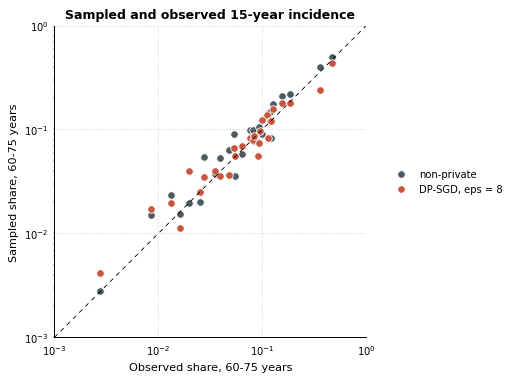

In [41]:
share, sampled = sampling_shares(models, test, TOKS, V, DEVICE)
plot_sampling(share, sampled, TOKS, V)

## 11. Synthetic cohorts

We let each model generate as many synthetic people as there are training members, from birth. A cohort from the
DP-SGD model keeps its guarantee, since sampling is post-processing. We compare the synthetic cohorts with the real
members for incidence by age and sex, for the known links (rate ratios adjusted for age with the Mantel-Haenszel
method, ages 40-80), and for copying: the copying test asks whether planted patients have a closer synthetic match
than kept-aside patients, and the DCR check whether synthetic people are closer to training members than to
non-members.

The rate ratios in the real members differ from the simulation's own for links that share a lifestyle cause (tobacco
use and lung cancer both follow smoking), because the Mantel-Haenszel estimate adjusts for age only; what matters
here is whether a synthetic cohort reproduces the members' ratios. In the last table, synthetic people are followed
to death or 85 years and members only to 2022 at the latest, so a synthetic cohort has more diagnoses per person
even when its rates are right; the events per person-year between 40 and 70 compare the rates themselves.

In [42]:
# a fixed seed, so that a rerun gives the same synthetic people
synth = {}
for name, m in models.items():
    synth[name] = ModelGenerator(m, DEVICE, 1024).sample(V, len(members), seed=5)

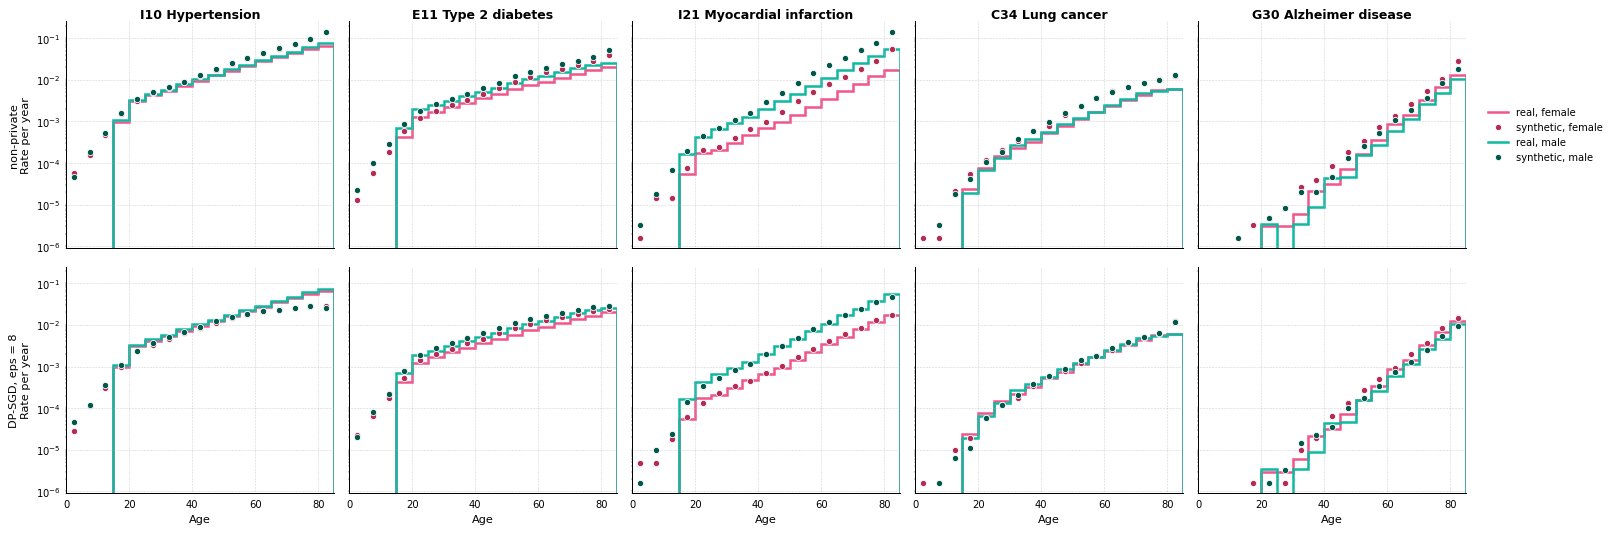

In [43]:
plot_synthetic_incidence(synth, by_sex, sel, bins, NAME)

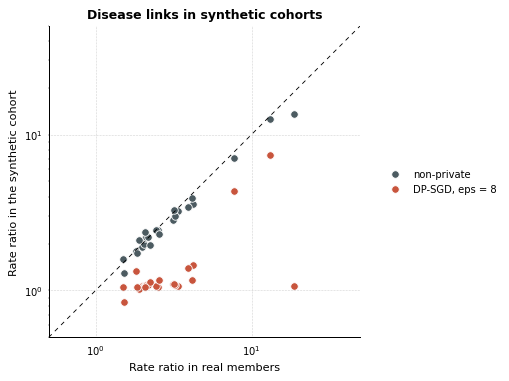

In [44]:
assoc = association_table(members, synth, LINKS, DISEASES, V)
plot_associations(assoc)

In [45]:
assoc.round(2)

,link,true,real,"synthetic, non-private","synthetic, DP-SGD, eps = 8"
0,Obesity -> Type 2 diabetes,3.0,3.39,3.24,1.07
1,Obesity -> Hypertension,2.0,1.99,1.90,1.06
2,Obesity -> Knee osteoarthritis,2.0,2.05,1.99,1.07
3,Obesity -> Sleep disorder,2.5,2.51,2.44,1.05
4,Hypertension -> Myocardial infarction,2.0,2.06,2.15,1.06
5,Hypertension -> Stroke,2.5,2.44,2.45,1.07
6,Hypertension -> Chronic kidney disease,2.0,2.11,2.21,1.08
7,Hypertension -> Heart failure,2.0,2.17,2.22,1.08
8,Type 2 diabetes -> Myocardial infarction,2.0,2.23,1.96,1.14
9,Type 2 diabetes -> Chronic kidney disease,3.0,3.12,2.85,1.11


In [46]:
copying, cp = copying_table(synth, planted, members, nonmembers, V)
copying.round(3)

,non-private,"DP-SGD, eps = 8"
"copying test, planted 8x: AUC",0.667,0.517
"copying test, planted once: AUC",0.560,0.575
DCR: share closer to a member,0.360,0.366
diagnoses per person (real 4.97),7.615,7.022
"events per person-year, 40-70 years (real 0.103)",0.162,0.121


Only the non-private cohort copies the patients planted eight times detectably (AUC 0.67 against 0.52 for DP-SGD).
For the patients planted once, both cohorts give AUCs of 0.56 to 0.58, so in this simulation, where the planted
patients are made of common codes, the copying test does not separate the two models for a history seen once. The
DCR check gives about 0.36 for both cohorts, so it does not tell them apart either. Both cohorts have too many
events: 0.162 (non-private) and 0.121 (DP-SGD) events per person-year at 40-70 years, against 0.103 in the members,
although both models are calibrated on real histories (sections 5, 6 and 10). We think the reason is that synthetic
people never receive lifestyle tokens: in the simulation, a person aged 40-70 without a visit record is one who dies
or leaves follow-up before the visit, so the model raises their rates. We have not tested this. Section 12 corrects
the rate level of the DP-SGD model with one factor.

## 12. Rate calibration

DP-SGD noise can move a private model's overall rate level. We calibrate by multiplying every rate by one factor
(one constant added to every logit), chosen so that synthetic people have the real number of disease events per
person-year between 40 and 70; we release the real number with the Laplace mechanism at $\varepsilon$ = 0.01.

In [47]:
m = models[PRIVATE]
real = dp_real_rate(members, V, eps=0.01, seed=0)
events, person_years = window_rate(synth[PRIVATE], V)

In [48]:
hist = calibrate(m, V, real['rate'], DEVICE, n=3000, iters=4, batch=1024, seed=0, log=print)

  calibration step 1: scale x1.000, synthetic 0.1214 vs real 0.1036 events/person-year (ratio 0.854)
  calibration step 2: scale x0.854, synthetic 0.1024 vs real 0.1036 events/person-year (ratio 1.012)
  calibration step 3: scale x0.864, synthetic 0.1051 vs real 0.1036 events/person-year (ratio 0.986)
  calibration step 4: scale x0.858, synthetic 0.1027 vs real 0.1036 events/person-year (ratio 1.009)
  kept scale x0.858 (synthetic/real ratio 1.009; slope 2.30)


In [49]:
pd.Series({'real rate (noisy)': real['rate'], 'synthetic before': events / person_years,
           'factor kept': np.exp(m.c.log_scale)})

real rate (noisy)    0.103627
synthetic before     0.121394
factor kept          0.858320
dtype: float64

One constant on every logit leaves every ranking unchanged, so every AUC should be exactly what it was in section 7
on the same people, records and controls. We check it, and then set the model back to its own rates.

In [50]:
# we reset the scale afterwards, so that rerunning a cell above uses the model's own rates
unchanged = aucs_unchanged(m, test, TOKS, auc, NAME, DEVICE, cfg['max_events'])
m.c.log_scale = 0.0
unchanged

True

## 13. The main numbers

The table collects the main numbers of the run: accuracy (the mean AUC over the codes with a cause, and the share of
the true rate's gain over 0.5 that each model reaches), the share of the learned link effects that DP-SGD keeps,
and the privacy audit, where an attack AUC of 0.5 means no memorization and the empirical lower bound on
$\varepsilon$ is set against the claimed one. The paper's results come from 251,204 UK Biobank members and are in its
figures and Supplementary Data 1.

In [51]:
summary_table(auc, links, audits, extras, cp).round(3)

,non-private,"DP-SGD, eps = 8"
"mean AUC, codes with a cause",0.639177,0.574788
true rate,0.652294,0.652294
share of the true rate's gain over 0.5,0.913869,0.491073
"mean AUC, all codes",0.588661,0.554641
share of the learned link effect,1.0,0.326397
reference attack AUC,0.53924,0.502386
planted 8x AUC,0.9848,0.5452
one-run lower bound on eps,0.869145,0.0
claimed eps,none,7.99
copying test AUC (8x),0.6666,0.5169


In [52]:
'notebook ran in %.1f min on %s' % ((time.time() - T0) / 60, DEVICE)

'notebook ran in 95.2 min on cuda'